<a href="https://colab.research.google.com/github/SoulDataLab/CODSOFT_TASKSNO/blob/main/CodSoft_Task3_Customer_Segmentation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import files

# Cleaned dataset upload karne ke liye (Agar local system se karna hai)
uploaded = files.upload()

# Dataset load karna
file_path = "cleaned_marketing_campaign.csv"
df = pd.read_csv(file_path)

print("Dataset successfully loaded for Task 3!")
print(f"Shape: {df.shape}")
df.head(3)

Saving cleaned_marketing_campaign.csv to cleaned_marketing_campaign.csv
Dataset successfully loaded for Task 3!
Shape: (2053, 27)


,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Response
0,5524,1957,Graduation,Single,58138.0,0,0,04-09-2012,58,635,...,10,4,7,0,0,0,0,0,0,1
1,2174,1954,Graduation,Single,46344.0,1,1,08-03-2014,38,11,...,1,2,5,0,0,0,0,0,0,0
2,4141,1965,Graduation,Together,71613.0,0,0,21-08-2013,26,426,...,2,10,4,0,0,0,0,0,0,0


In [2]:
from sklearn.preprocessing import StandardScaler

# Customer segmentation ke liye zaroori features select karna (Jaise Age, Income, Total Spend)
# Pehle 'Age' nikal lete hain Year_Birth se
df['Age'] = 2026 - df['Year_Birth']
df['Total_Spent'] = df['MntWines'] + df['MntFruits'] + df['MntMeatProducts'] + df['MntFishProducts'] + df['MntSweetProducts'] + df['MntGoldProds']

# Numerical features chunna clustering ke liye
X = df[['Income', 'Age', 'Total_Spent', 'NumWebPurchases', 'NumStorePurchases']].dropna()

# Data scale karna
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Features selected and scaled successfully!")
print(f"Clustering data shape: {X_scaled.shape}")

Features selected and scaled successfully!
Clustering data shape: (2053, 5)


In [3]:
from sklearn.cluster import KMeans

# 4 clusters mein divide karna (Customer segments)
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
df.loc[X.index, 'Cluster'] = kmeans.fit_predict(X_scaled)

print("K-Means Clustering completed!")
print(df['Cluster'].value_counts())

K-Means Clustering completed!
Cluster
0.0    676
3.0    549
2.0    426
1.0    402
Name: count, dtype: int64


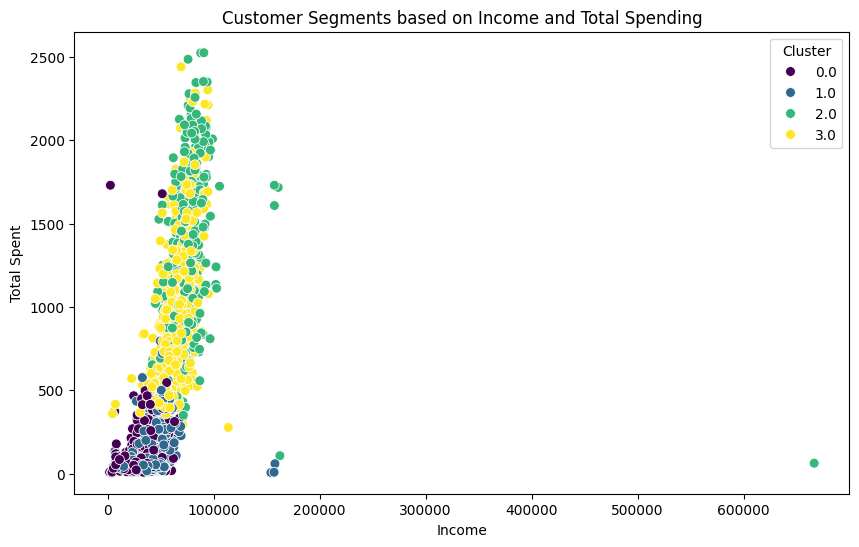

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))
sns.scatterplot(x=X['Income'], y=X['Total_Spent'], hue=df.loc[X.index, 'Cluster'], palette='viridis', s=50)
plt.title('Customer Segments based on Income and Total Spending')
plt.xlabel('Income')
plt.ylabel('Total Spent')
plt.legend(title='Cluster')
plt.show()

In [5]:
output_file_name = "segmented_marketing_campaign.csv"
df.to_csv(output_file_name, index=False)
print(f"Segmented dataset successfully saved as '{output_file_name}'.")

Segmented dataset successfully saved as 'segmented_marketing_campaign.csv'.
